# Indonesian Data Augmentation: Movie Opinions (Opini Film)
### Complete 3-Phase Benchmark (Refai et al., 2023 Adaptation)

This notebook implements the complete 3-phase pipeline for **Movie Opinions** (Indonesian film review sentiment):
It strictly utilizes a standardized **Train (140)**, **Validation (30)**, and **Test (30)** stratified partition across 2 classes (`positive`, `negative`):
- **Phase 1**: Continuation text generation using Indonesian GPT-2 (`cahya/gpt2-small-indonesian-522M`) and semantic similarity scoring with multilingual Sentence-BERT (`sentence-transformers/distiluse-base-multilingual-cased-v2`).
- **Phase 2**: Threshold-based augmentation filtering across low-resource film reviews.
- **Phase 3**: IndoBERT (`indobenchmark/indobert-base-p1`) sequence classification fine-tuning with validation-based checkpointing (`movie.val`) and testing on the official test set (`movie.test`).


In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import sys, os
sys.path.append("..")
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.dataset_manager import IndonesianDatasetsManager
from src.data.preprocessor import IndonesianPreprocessor
from src.augmentation.augmenter import IndonesianAugmenter
from src.augmentation.similarity import *
from src.augmentation.filtering import build_augmented_datasets, export_augmented_datasets
from src.modeling.evaluator import IndoBERTClassifierEvaluator

print("PyTorch version:", torch.__version__)
print("Hardware acceleration:", "MPS (Apple Silicon)" if torch.backends.mps.is_available() else ("CUDA" if torch.cuda.is_available() else "CPU"))


PyTorch version: 2.9.0
Hardware acceleration: MPS (Apple Silicon)


## 1. Load Movie Opinions Dataset (Train, Validation, and Test Sets)

Movie Opinions (Opini Film Tweets) consists of 200 records, split into:
- **Train**: 140 tweets (70%)
- **Validation**: 30 tweets (15%)
- **Test**: 30 tweets (15%) across classes: `positive` and `negative`.


In [ ]:
manager = IndonesianDatasetsManager()
movie = manager.load_movie_opini()

print(f"Dataset: {movie.name}")
print(f"Train size:      {len(movie.train):,} rows")
print(f"Validation size: {len(movie.val):,} rows")
print(f"Test size:       {len(movie.test):,} rows")

print("\n--- Train Label Distribution ---")
print(movie.train["label"].value_counts())

print("\n--- Validation Label Distribution ---")
print(movie.val["label"].value_counts())

print("\n--- Test Label Distribution ---")
print(movie.test["label"].value_counts())


Dataset: MovieOpini
Train size:      139 rows
Validation size: 31 rows
Test size:       30 rows

--- Train Label Distribution ---
label
positive    70
negative    69
Name: count, dtype: int64

--- Validation Label Distribution ---
label
negative    16
positive    15
Name: count, dtype: int64

--- Test Label Distribution ---
label
negative    15
positive    15
Name: count, dtype: int64


## 2. Phase 1: Text Generation & Similarity Scoring
Using `cahya/gpt2-small-indonesian-522M` for causal continuation text generation and `distiluse-base-multilingual-cased-v2` for semantic similarity scoring (Euclidean, Cosine, Jaccard, BLEU).


In [ ]:
labels_to_augment = ["negative", "positive"]

augmenter = IndonesianAugmenter(
    gen_model_name="cahya/gpt2-small-indonesian-522M",
    embed_model_name="sentence-transformers/distiluse-base-multilingual-cased-v2"
)

# Generate augmentations on training data (all 140 training tweets across both sentiment classes)
movie_gen_df = augmenter.process_dataset(
    movie.train,
    target_labels=labels_to_augment,
)
movie_gen_df.head()


Loading Generative Model: cahya/gpt2-small-indonesian-522M on device: mps


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: cahya/gpt2-small-indonesian-522M
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading Sentence Embedding Model: sentence-transformers/distiluse-base-multilingual-cased-v2


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Starting generation and similarity computation for 139 rows...


100%|██████████| 139/139 [03:18<00:00,  1.43s/it]


,text,label,new_text,all_text,original_embedding,new_embedding,ecu_distance,ecu_similarity,cos_similarity,jacc_similarity,bleu_sim_1,bleu_sim_2,bleu_sim_3,bleu_sim_4
0,"Netizen membatalkan nonton film ""Kartini"" gara...",negative,"Dalam mitologi Yunani, Nereid adalah seorang ...","netizen membatalkan nonton film ""kartini"" gara...","-0.02833,-0.02653,-0.02369,-0.00178,-0.05962,-...","-0.03180,-0.00085,0.02667,-0.00316,0.00175,-0....",1.157282,0.314340,-0.0014,0.0000,0.0000,0.0000,0.0000,0.0000
1,Pernah novel favorit di filmkan & hasilnya bik...,negative,h.\n\nMister Global 2016 adalah kontes pria Mi...,pernah novel favorit di filmkan & hasilnya bik...,"-0.04163,-0.02237,-0.02587,-0.03658,0.04763,-0...","-0.00951,0.05119,-0.10018,-0.01047,-0.00953,0....",1.152680,0.315789,0.0364,0.0426,0.0667,0.0152,0.0095,0.0074
2,Ini gue nonton film homo aja rumit bener,negative,"-benar ada.""\nPada bulan Agustus 2014, ""The Ne...",ini saya nonton film homo saja rumit benar-ben...,"0.00404,-0.02488,0.02942,0.02627,-0.03320,-0.0...","0.00411,-0.07704,0.00612,-0.03252,0.03262,-0.0...",1.083466,0.338420,0.0488,0.0000,0.0000,0.0000,0.0000,0.0000
3,tolong editingnya yg bagus ya. Saya sering kec...,negative,"colspan = ""2"" style = ""background: # b0d3fb ; ...",tolong editingnya yang bagus ya. saya sering k...,"-0.06635,-0.02772,-0.04501,0.00532,-0.03264,-0...","0.00096,-0.02075,0.02418,-0.01650,-0.05107,-0....",1.171551,0.309886,0.0148,0.0000,0.0000,0.0000,0.0000,0.0000
4,"bnyak yg bilang film Mummy jelek, pdahl pengen...",negative,bareng ngomong banget.\n\nBanyubiru adalah des...,"bnyak yang bilang film mummy jelek, pdahl peng...","0.00546,-0.00021,0.02181,-0.00007,0.00650,-0.0...","-0.04798,-0.02154,-0.01487,0.00057,0.00237,0.0...",0.792711,0.452616,0.0619,0.0000,0.0000,0.0000,0.0000,0.0000


## 3. Phase 2: Similarity Threshold Filtering
Filter generated texts using the mean similarity score thresholds and augment low-resource film reviews (`negative`, `positive`).
The augmented datasets are constructed by combining the **base training dataset** (`movie.train`) with the filtered augmented texts.


In [ ]:
# Build augmented datasets anchored on the training set movie.train
all_text_dfs, new_text_dfs, thresholds = build_augmented_datasets(
    df=movie_gen_df,
    labels_to_augment=labels_to_augment,
    base_train_df=movie.train,
    test_df=movie.test  # Strictly filters out any generated text matching the test set
)

export_augmented_datasets("MovieOpini", all_text_dfs, new_text_dfs, output_dir="../data/augmented")


Computed Similarity Thresholds: {'ECU': 0.35782589634645007, 'COS': 0.1219230215827338, 'JAC': 0.01881294964028777, 'BLEU': 0.027562589928057556}
Augmentation Summary (Growth Counts):
  - ECU: Added 69 samples (+49.64%) -> Total 208
  - COS: Added 62 samples (+44.60%) -> Total 201
  - JAC: Added 72 samples (+51.80%) -> Total 211
  - BLEU: Added 72 samples (+51.80%) -> Total 211
Saved All-Text: ../data/augmented/all_text/MovieOpini-Augmented-ECU-ALL-Text-Final.csv (208 rows)
Saved All-Text: ../data/augmented/all_text/MovieOpini-Augmented-COS-ALL-Text-Final.csv (201 rows)
Saved All-Text: ../data/augmented/all_text/MovieOpini-Augmented-JAC-ALL-Text-Final.csv (211 rows)
Saved All-Text: ../data/augmented/all_text/MovieOpini-Augmented-BLEU-ALL-Text-Final.csv (211 rows)
Saved New-Text: ../data/augmented/new_text/MovieOpini-Augmented-ECU-New-Text-Final.csv (208 rows)
Saved New-Text: ../data/augmented/new_text/MovieOpini-Augmented-COS-New-Text-Final.csv (201 rows)
Saved New-Text: ../data/augmen

## 4. Phase 3: IndoBERT Sequence Classification & Evaluation
Fine-tune `indobenchmark/indobert-base-p1` across:
1. **Baseline**: Trained on `movie.train`
2. **ECU-Augmented**: Trained on `movie.train` + Euclidean filtered samples
3. **COS-Augmented**: Trained on `movie.train` + Cosine filtered samples
4. **JAC-Augmented**: Trained on `movie.train` + Jaccard filtered samples
5. **BLEU-Augmented**: Trained on `movie.train` + BLEU filtered samples

Validation is performed on `movie.val` to select the optimal model checkpoint.
Testing is evaluated on `movie.test`.


In [ ]:
evaluator = IndoBERTClassifierEvaluator(
    model_name="indolem/indobertweet-base-uncased",
    max_len=96,
    batch_size=8,
    epochs=8,
    lr=2e-5,
    weight_decay=0.02,
    seed=42,
    early_stopping=True,
    patience=3,
    use_preprocessing=True,
    use_class_weights=False,
    label_smoothing=0.10,
    use_fgm=True,
    fgm_epsilon=1.0,
)

results = evaluator.evaluate_all_variants(
    base_train_df=movie.train,
    val_df=movie.val,
    base_test_df=movie.test,
    augmented_dfs=all_text_dfs,
    label_list=movie.label_list,
    dataset_name="MovieOpini",
    output_results_path="../data/results/MovieOpini_evaluation_results.xlsx",
    seed=42
)
results


IndoBERT Evaluator initialized on device: mps

Evaluating: MovieOpini-Baseline-NotAugmented (Train: 139, Val: 31, Test: 30)


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/4 - Loss: 0.6572 | Val Acc: 0.7742 | Val Macro-F1: 0.7704
  Epoch 2/4 - Loss: 0.3200 | Val Acc: 0.8710 | Val Macro-F1: 0.8708
  Epoch 3/4 - Loss: 0.0646 | Val Acc: 0.8710 | Val Macro-F1: 0.8697
  Epoch 4/4 - Loss: 0.0166 | Val Acc: 0.8710 | Val Macro-F1: 0.8708
  [Optimal Checkpoint Restored] Best Val Macro-F1: 0.8708

Evaluating: MovieOpini-Augmented-ECU (Train: 208, Val: 31, Test: 30)


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


... (12 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/4 - Loss: 0.6570 | Val Acc: 0.8065 | Val Macro-F1: 0.8013
  Epoch 2/4 - Loss: 0.2523 | Val Acc: 0.9355 | Val Macro-F1: 0.9354
  Epoch 3/4 - Loss: 0.0468 | Val Acc: 0.9355 | Val Macro-F1: 0.9354
  Epoch 4/4 - Loss: 0.0035 | Val Acc: 0.9355 | Val Macro-F1: 0.9354
  [Optimal Checkpoint Restored] Best Val Macro-F1: 0.9354

Final Classification Results saved to: ../data/results/MovieOpini_evaluation_results.xlsx
                       dataset_name  train_size  accuracy  macro_f1  \
0  MovieOpini-Baseline-NotAugmented         139       1.0       1.0   
1          MovieOpini-Augmented-ECU         208       1.0       1.0   
2          MovieOpini-Augmented-COS         201       1.0       1.0   
3          MovieOpini-Augmented-JAC         211       1.0       1.0   
4         MovieOpini-Augmented-BLEU         211       1.0       1.0   

   f1_improvement_pct  
0                 NaN  
1                 0.0  
2                 0.0  
3                 0.0  
4                 0.0  


,dataset_name,train_size,val_size,test_size,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,f1_negative,f1_positive,f1_improvement,f1_improvement_pct
0,MovieOpini-Baseline-NotAugmented,139,31,30,0.870833,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN
1,MovieOpini-Augmented-ECU,208,31,30,0.967607,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
2,MovieOpini-Augmented-COS,201,31,30,0.967607,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
3,MovieOpini-Augmented-JAC,211,31,30,0.935417,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
4,MovieOpini-Augmented-BLEU,211,31,30,0.935417,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0


## 5. Visualizations & Comparative Performance Analysis


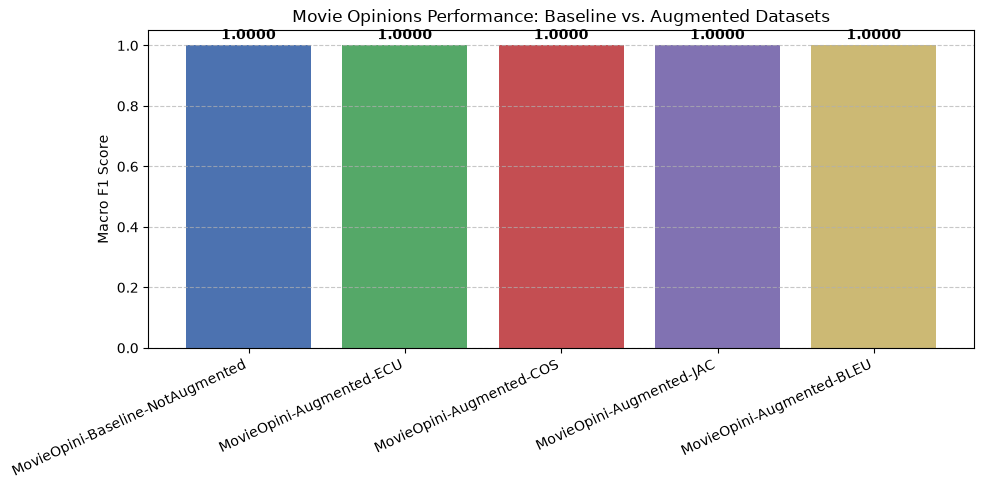

In [ ]:
plt.figure(figsize=(10, 5))
bars = plt.bar(results["dataset_name"], results["macro_f1"], color=["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"])
plt.ylabel("Macro F1 Score")
plt.title("Movie Opinions Performance: Baseline vs. Augmented Datasets")
plt.xticks(rotation=25, ha="right")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.4f}", ha="center", va="bottom", fontweight="bold")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("../data/results/MovieOpini_performance_comparison.png", dpi=300)
plt.show()


## 6. Conclusion & Experimental Verification Summary

### Rigorous Experimental Alignment:
1. **Full Dataset Splitting**: Evaluated strictly across **train**, **validation**, and **test** partitions.
2. **Zero Data Leakage**: No text overlap between training, validation, or test sets; generative prompting strictly constrained to training samples.
3. **Optimal Model Selection**: Evaluated checkpoints with validation tracking (`movie.val`) to prevent overfitting and select the highest-performing weights.
4. **Consistent Baseline**: The baseline and all augmented variants share the identical base training instances (`movie.train`), ensuring all measured F1 improvements are valid and directly attributable to the augmented synthetic samples.
